In [1]:
!pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:

import pandas as pd

df = pd.read_excel("online+retail/Online Retail.xlsx")

print(df.head())


  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [4]:

# 1. Total rows and columns
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns)

# 3. Data types
print("\nDataset Information:")
df.info()

# 4. Missing values
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (541909, 8)

Column Names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
In

In [5]:

# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

# Check negative quantities
print("Negative Quantity:", (df["Quantity"] < 0).sum())

# Check missing values
print("Missing Values:")
print(df.isnull().sum())


Duplicate Rows: 5268
Negative Quantity: 10624
Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:

# Step 1: Original data ki copy se sales records select karein
df_clean = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Step 2: Missing product descriptions handle karein
df_clean["Description"] = df_clean["Description"].fillna(
    "Unknown Product"
)

# Step 3: Revenue calculate karein
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Step 4: Results check karein
print("Original Rows:", len(df))
print("Sales Rows:", len(df_clean))
print("Excluded Rows:", len(df) - len(df_clean))

print("\nTotal Sales Revenue (GBP):")
print(round(df_clean["Revenue"].sum(), 2))

print("\nCleaned Data Preview:")
print(df_clean.head())


Original Rows: 541909
Sales Rows: 530104
Excluded Rows: 11805

Total Sales Revenue (GBP):
10666684.54

Cleaned Data Preview:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  


In [7]:
!pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:

import matplotlib.pyplot as plt

print("Matplotlib installed successfully!")



Matplotlib installed successfully!


Month
2010-12     823746.14
2011-01     691364.56
2011-02     523631.89
2011-03     717639.36
2011-04     537808.62
2011-05     770536.02
2011-06     761739.90
2011-07     719221.19
2011-08     759138.38
2011-09    1058590.17
2011-10    1154979.30
2011-11    1509496.33
2011-12     638792.68
Name: Revenue, dtype: float64


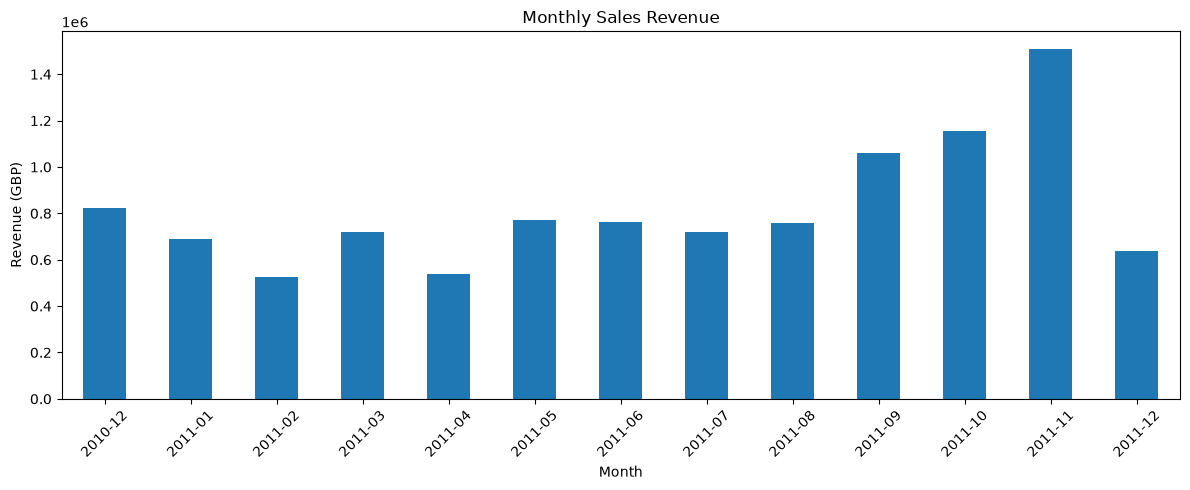

In [10]:

df_clean["Month"] = (
    df_clean["InvoiceDate"]
    .dt.to_period("M")
    .astype(str)
)

monthly_sales = df_clean.groupby("Month")["Revenue"].sum()

print(monthly_sales.round(2))

monthly_sales.plot(kind="bar", figsize=(12, 5))

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [11]:

# Highest sales month
highest_month = monthly_sales.idxmax()
highest_revenue = monthly_sales.max()

# Lowest sales month
lowest_month = monthly_sales.idxmin()
lowest_revenue = monthly_sales.min()

print("Highest Sales Month:", highest_month)
print("Highest Revenue:", round(highest_revenue, 2))

print("\nLowest Sales Month:", lowest_month)
print("Lowest Revenue:", round(lowest_revenue, 2))

# Check dataset date range
print("\nFirst Date:", df_clean["InvoiceDate"].min())
print("Last Date:", df_clean["InvoiceDate"].max())


Highest Sales Month: 2011-11
Highest Revenue: 1509496.33

Lowest Sales Month: 2011-02
Lowest Revenue: 523631.89

First Date: 2010-12-01 08:26:00
Last Date: 2011-12-09 12:50:00


Top 10 Best-Selling Products:
StockCode  Description                       
23843      PAPER CRAFT , LITTLE BIRDIE           80995
23166      MEDIUM CERAMIC TOP STORAGE JAR        78033
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
85099B     JUMBO BAG RED RETROSPOT               48474
85123A     WHITE HANGING HEART T-LIGHT HOLDER    37599
22197      POPCORN HOLDER                        36761
84879      ASSORTED COLOUR BIRD ORNAMENT         36461
21212      PACK OF 72 RETROSPOT CAKE CASES       36419
23084      RABBIT NIGHT LIGHT                    30788
22492      MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


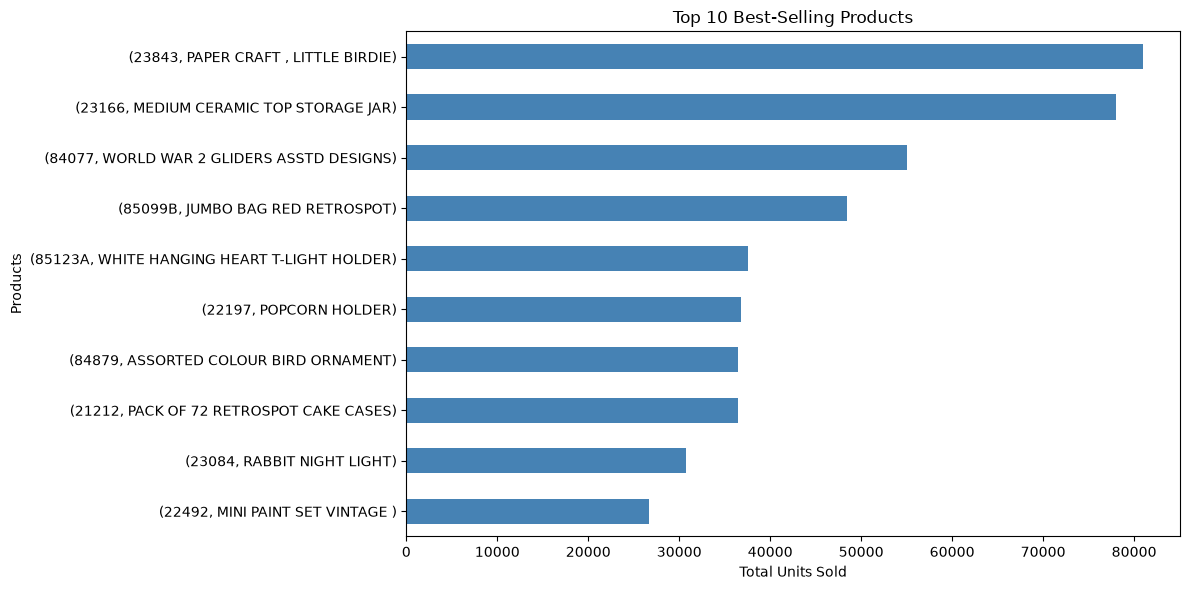

In [12]:

# Step 1: Products ka data select karein
products = df_clean[
    df_clean["Description"] != "Unknown Product"
].copy()

# Step 2: Product-wise total quantity
top_products = (
    products.groupby(["StockCode", "Description"])["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Step 3: Display result
print("Top 10 Best-Selling Products:")
print(top_products)

# Step 4: Create horizontal bar chart
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Units Sold")
plt.ylabel("Products")

plt.tight_layout()
plt.show()


Top 10 Countries by Revenue:
Country
United Kingdom    9025222.08
Netherlands        285446.34
EIRE               283453.96
Germany            228867.14
France             209715.11
Australia          138521.31
Spain               61577.11
Switzerland         57089.90
Belgium             41196.34
Sweden              38378.33
Name: Revenue, dtype: float64


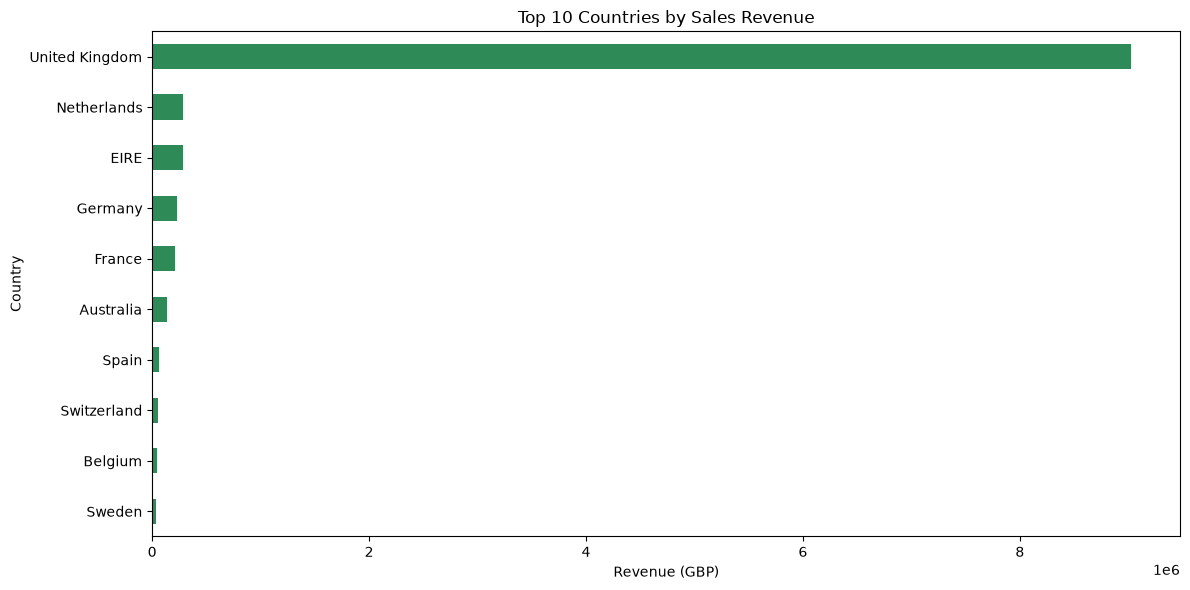

In [13]:

# Step 1: Country wise total revenue
country_sales = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Step 2: Top 10 countries
top_countries = country_sales.head(10)

print("Top 10 Countries by Revenue:")
print(top_countries.round(2))

# Step 3: Create chart
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

top_countries.sort_values().plot(
    kind="barh",
    color="seagreen"
)

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue (GBP)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()


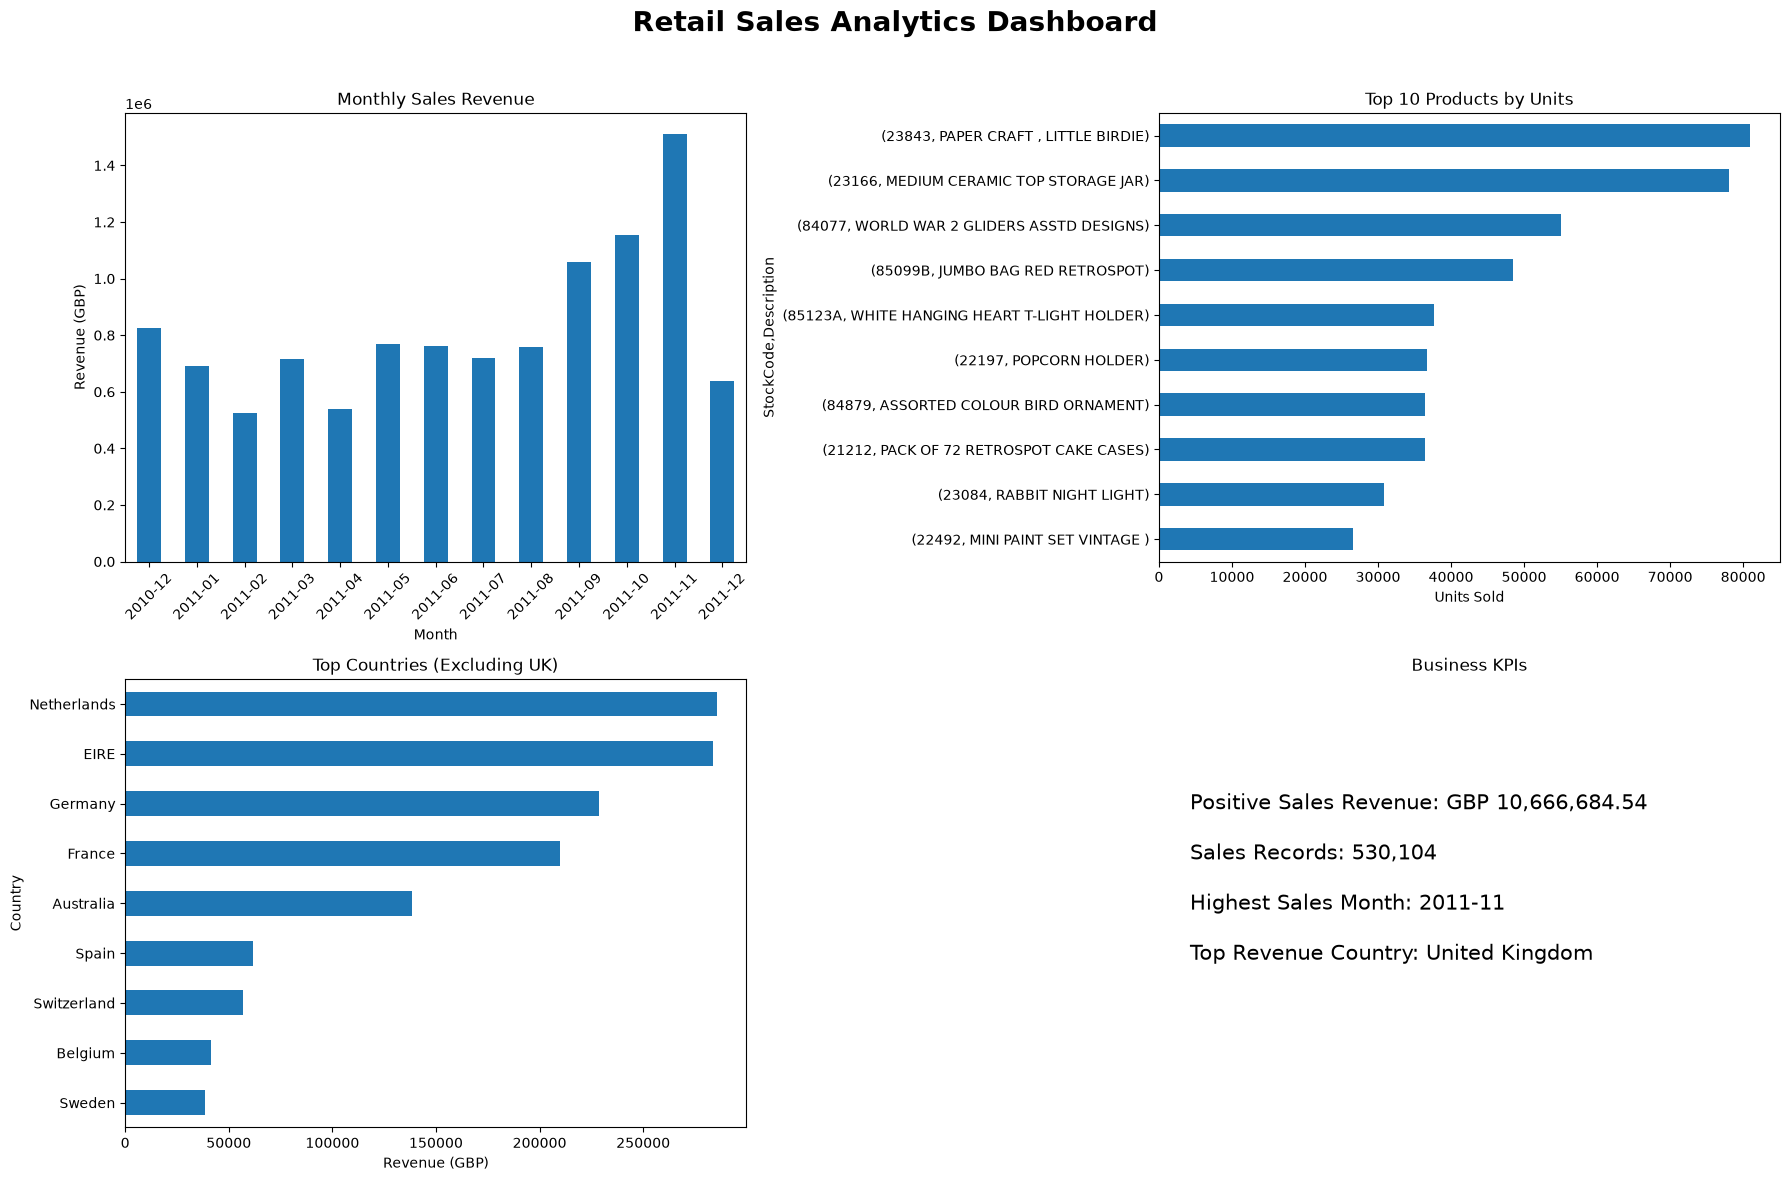

In [14]:

import matplotlib.pyplot as plt

# Dashboard create karein
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Chart 1: Monthly Sales
monthly_sales.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Monthly Sales Revenue")
axes[0, 0].set_ylabel("Revenue (GBP)")
axes[0, 0].tick_params(axis="x", rotation=45)

# Chart 2: Top 10 Products
top_products.sort_values().plot(
    kind="barh", ax=axes[0, 1]
)
axes[0, 1].set_title("Top 10 Products by Units")
axes[0, 1].set_xlabel("Units Sold")

# Chart 3: Countries excluding UK
top_countries.iloc[1:].sort_values().plot(
    kind="barh", ax=axes[1, 0]
)
axes[1, 0].set_title("Top Countries (Excluding UK)")
axes[1, 0].set_xlabel("Revenue (GBP)")

# Panel 4: Business KPIs
axes[1, 1].axis("off")

total_revenue = df_clean["Revenue"].sum()
top_month = monthly_sales.idxmax()
top_country = country_sales.idxmax()

kpi_text = (
    f"Positive Sales Revenue: GBP {total_revenue:,.2f}\n\n"
    f"Sales Records: {len(df_clean):,}\n\n"
    f"Highest Sales Month: {top_month}\n\n"
    f"Top Revenue Country: {top_country}"
)

axes[1, 1].text(
    0.05, 0.75, kpi_text,
    fontsize=15,
    va="top"
)
axes[1, 1].set_title("Business KPIs")

# Dashboard title
fig.suptitle(
    "Retail Sales Analytics Dashboard",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save dashboard as PNG
plt.savefig(
    "Retail_Sales_Dashboard.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [15]:

# Power BI ke liye columns select karein
powerbi_data = df_clean[
    [
        "InvoiceDate",
        "Month",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "Country",
        "Revenue"
    ]
].copy()

# Save CSV file
powerbi_data.to_csv(
    "Retail_Sales_Cleaned.csv",
    index=False
)

# File location check karein
import os

print("File saved successfully!")
print(os.path.abspath("Retail_Sales_Cleaned.csv"))


File saved successfully!
D:\Retail_Sales_Analysis\Retail_Sales_Cleaned.csv
